# Q1 — Regression from scratch (10 p)
Models: **Linear** (1 feature) · **Multiple** · **Poly** · **Better**
Better = picks automatically (5-fold CV on train) the strongest of: Poly2+Ridge, Random Forest, or their average.
Only numpy. Change the 3 lines marked `# <<<` in cell 1, then Run All.

## 1. Load + clean + split (80 / 20)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../titanic.csv")                       # <<< file
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch"]         # <<< features (x)
target = "Fare"                                           # <<< what to predict (y)

df["Sex"] = df["Sex"].map({"male": 1, "female": 0})       # text -> number (see 2_DATA_PREP)
df = df[cols + [target]]
df = df.dropna(subset=[target])                           # never fill y
df = df.fillna(df.median())                               # fill missing x with median
df = df.sample(frac=1, random_state=42)                   # shuffle

x = df[cols].values.astype(float)
y = df[target].values.astype(float)

n = int(len(df) * 0.8)
x_train, x_test, y_train, y_test = x[:n], x[n:], y[:n], y[n:]
print("train", x_train.shape, "test", x_test.shape)

train (712, 5) test (179, 5)


## 2. Models (from scratch)

In [2]:
def r2(y_true, y_pred):
    return 1 - ((y_true - y_pred) ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum()


def linear(x_train, y_train, x_test):
    x_train = np.column_stack([np.ones(len(x_train)), x_train])
    x_test = np.column_stack([np.ones(len(x_test)), x_test])
    w = np.linalg.pinv(x_train.T @ x_train) @ x_train.T @ y_train
    return x_test @ w


def poly(x):                                              # x, x^2
    return np.column_stack([x, x ** 2])


def poly2(x):                                             # x, x^2 and every xi*xj (stronger poly)
    out = [x]
    for i in range(x.shape[1]):
        for j in range(i, x.shape[1]):
            out.append(x[:, [i]] * x[:, [j]])
    return np.hstack(out)


def ridge(x_train, y_train, x_test, lam=1):              # linear + small penalty -> poly2 does not overfit
    mu, sd = x_train.mean(0), x_train.std(0) + 1e-9
    a = np.column_stack([np.ones(len(x_train)), (x_train - mu) / sd])
    b = np.column_stack([np.ones(len(x_test)), (x_test - mu) / sd])
    i = np.eye(a.shape[1]); i[0, 0] = 0
    w = np.linalg.pinv(a.T @ a + lam * i) @ a.T @ y_train
    return b @ w


def tree(x, y, depth):                                    # one regression tree
    if depth == 0 or len(y) < 10:
        return y.mean()
    best_loss, best = ((y - y.mean()) ** 2).sum(), None
    for j in range(x.shape[1]):
        for t in np.unique(np.percentile(x[:, j], range(5, 100, 5))):
            left = x[:, j] <= t
            if left.sum() < 5 or (~left).sum() < 5:
                continue
            loss = ((y[left] - y[left].mean()) ** 2).sum() + ((y[~left] - y[~left].mean()) ** 2).sum()
            if loss < best_loss:
                best_loss, best = loss, (j, t)
    if best is None:
        return y.mean()
    j, t = best
    left = x[:, j] <= t
    return (j, t, tree(x[left], y[left], depth - 1), tree(x[~left], y[~left], depth - 1))


def tree_predict(node, x):
    if not isinstance(node, tuple):
        return np.full(len(x), node)
    j, t, l, r = node
    left = x[:, j] <= t
    out = np.empty(len(x))
    out[left] = tree_predict(l, x[left])
    out[~left] = tree_predict(r, x[~left])
    return out


def forest(x_train, y_train, x_test, n_trees=50, depth=8):    # Random Forest = average of many trees
    rng = np.random.default_rng(42)
    preds = []
    for _ in range(n_trees):
        i = rng.integers(0, len(y_train), len(y_train))        # random sample of rows (with repeats)
        preds.append(tree_predict(tree(x_train[i], y_train[i], depth), x_test))
    return np.mean(preds, axis=0)


def cv(model, x, y, k=5):                                 # 5-fold cross-validation R2 (train only)
    folds = np.array_split(np.arange(len(y)), k)
    scores = []
    for f in folds:
        rest = np.setdiff1d(np.arange(len(y)), f)
        scores.append(r2(y[f], model(x[rest], y[rest], x[f])))
    return np.mean(scores)

## 3. Pick the Better model (CV on train, never on test)

In [3]:
better_options = {
    "Poly2 + Ridge":  lambda a, b, c: ridge(poly2(a), b, poly2(c)),
    "Random Forest":  forest,
    "Forest + Poly2": lambda a, b, c: (forest(a, b, c) + ridge(poly2(a), b, poly2(c))) / 2,
}
scores = {}
for name, f in better_options.items():
    scores[name] = cv(f, x_train, y_train)
    print(f"{name:15s} CV R2 = {scores[name]:.4f}")
better = max(scores, key=scores.get)
print("Better =", better)

Poly2 + Ridge   CV R2 = 0.4568


Random Forest   CV R2 = 0.3647


Forest + Poly2  CV R2 = 0.4465
Better = Poly2 + Ridge


## 4. Train + predict

In [4]:
# Linear uses the 1 feature most related to y
corr = [abs(np.corrcoef(x_train[:, j], y_train)[0, 1]) for j in range(x.shape[1])]
j = int(np.argmax(corr))
print("Linear uses:", cols[j])

pred = {
    "Linear":   linear(x_train[:, [j]], y_train, x_test[:, [j]]),
    "Multiple": linear(x_train, y_train, x_test),
    "Poly":     linear(poly(x_train), y_train, poly(x_test)),
    f"Better ({better})": better_options[better](x_train, y_train, x_test),
}

Linear uses: Pclass


## 5. Graphs + ranking

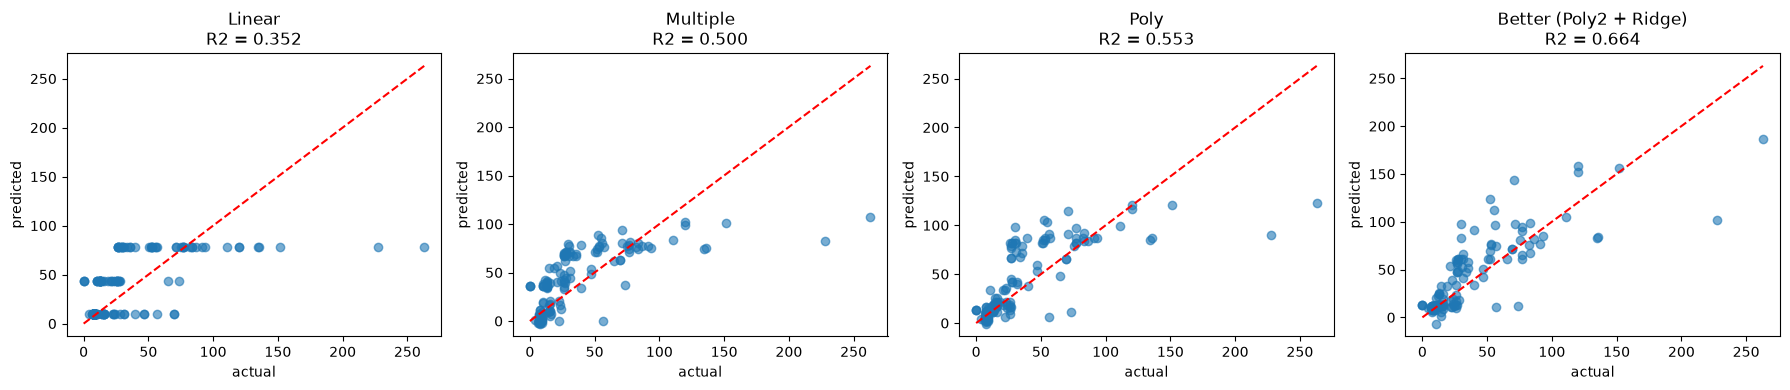

,model,R2
1,Better (Poly2 + Ridge),0.664031
2,Poly,0.552935
3,Multiple,0.500255
4,Linear,0.352399


In [5]:
plt.figure(figsize=(18, 4))
for i, (name, p) in enumerate(pred.items(), 1):
    plt.subplot(1, 4, i)
    plt.scatter(y_test, p, alpha=0.6)
    plt.plot([0, y_test.max()], [0, y_test.max()], "r--")
    plt.title(f"{name}\nR2 = {r2(y_test, p):.3f}")
    plt.xlabel("actual"); plt.ylabel("predicted")
plt.tight_layout()
plt.show()

rank = pd.DataFrame({"model": list(pred), "R2": [r2(y_test, p) for p in pred.values()]})
rank = rank.sort_values("R2", ascending=False).reset_index(drop=True)
rank.index += 1
rank

**Write under the table:** "Better (…) ranks first, R² = …. I chose it with 5-fold cross-validation on train. Poly2 adds squares and feature×feature terms, Ridge stops it from overfitting, and Random Forest averages many trees to catch non-linear patterns. Linear is worst because one feature can't explain the target."

If time is short on a big dataset: set `n_trees=20` in `forest(...)`.